# Week 7 - Clipping

In this lesson we will learn how to clip different geometries.

By the end of this lesson, you will be able to:

- reproject geo-dataframes so they share the same CRS 
- clip a `geopandas.GeoDataFrame` to the polygons of another one using `geopandas.clip()`
- subset tabular data before applying geospatial operations
- decide when to clip to a bounding box instead of the exact polygons

## About the data

We will use three datasets. Put each unzipped folder inside a `data/` folder at the same level as this notebook.

1. **US states**: the 2026 [TIGER shapefile of the US states](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html#form-dropdown-790442341) from the United States Census Bureau. You already have this dataset in your computer. 

2. **Populated places**: [Natural Earth's medium-scale populated places dataset (1:50m)](https://www.naturalearthdata.com/downloads/50m-cultural-vectors/). Under "Populated Places", download the simple version (the one that says "simple (less columns)"). You will get a `ne_50m_populated_places_simple` folder.

3. **Roads**: [Natural Earth's large-scale roads dataset (1:10m)](https://www.naturalearthdata.com/downloads/10m-cultural-vectors/roads/). Download the shapefile. You will get a `ne_10m_roads` folder.

Read the [lesson's "About the data" section](https://meds-eds-220.github.io/MEDS-eds-220-course/book/chapters/lesson-13-clipping/lesson-13-clipping.html#about-the-data) for more information about the datasets, including the column descriptions of the US states shapefile.

## Import data

Let's start by loading our libraries and then importing the datasets we will use.

In [7]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

from shapely.geometry import box  # To create polygon bounding box


pd.set_option("display.max.columns", None)

# -------------------------------------------------------
# === MODIFY AS NEEDED TO IMPORT YOUR DATA ===

# Import states polygons
states = gpd.read_file(os.path.join('/Users/kellyanne/Desktop/meds2027/eds220/eds220-in-class/data',
                                    'tl_2026_us_state', 
                                    'tl_2026_us_state.shp'))

# Import Natural Earth populated places points
places = gpd.read_file(os.path.join('/Users/kellyanne/Desktop/meds2027/eds220/eds220-in-class/data',
                                    'ne_50m_populated_places_simple',
                                    'ne_50m_populated_places_simple.shp')
                                    )

# Import roads lines
roads = gpd.read_file(os.path.join('/Users/kellyanne/Desktop/meds2027/eds220/eds220-in-class/data',
                                   'ne_10m_roads',
                                   'ne_10m_roads.shp')
                                   )

## Check-in (complete before class)
Use a `for` loop to iterate over the three geo-dataframes we imported and change their column names to lowercase.

In [44]:
for df in [states, places, roads]:
    df.columns = df.columns.str.lower()

We will combine these datasets to create the following map of infrastructure in Alaska:

![alt text](https://meds-eds-220.github.io/MEDS-eds-220-course/book/images/lesson-13/alaska.png)

<Axes: >

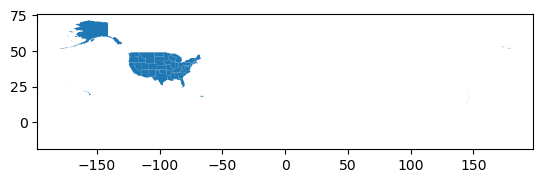

In [45]:
states.plot()

<Axes: >

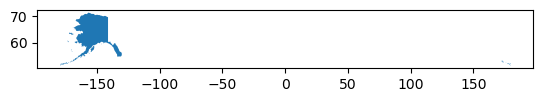

In [46]:
alaska = states[states['name'] == 'Alaska']
alaska.plot()

In [47]:
# Reproject to CRS optimized for Alaska
alaska = alaska.to_crs('epsg:3338')

# Inspect the new CRS
print('Is this CRS projected? ', alaska.crs.is_projected)
alaska.crs

Is this CRS projected?  True


<Projected CRS: EPSG:3338>
Name: NAD83 / Alaska Albers
Axis Info [cartesian]:
- X[east]: Easting (metre)
- Y[north]: Northing (metre)
Area of Use:
- name: United States (USA) - Alaska.
- bounds: (172.42, 51.3, -129.99, 71.4)
Coordinate Operation:
- name: Alaska Albers (meter)
- method: Albers Equal Area
Datum: North American Datum 1983
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

<Axes: >

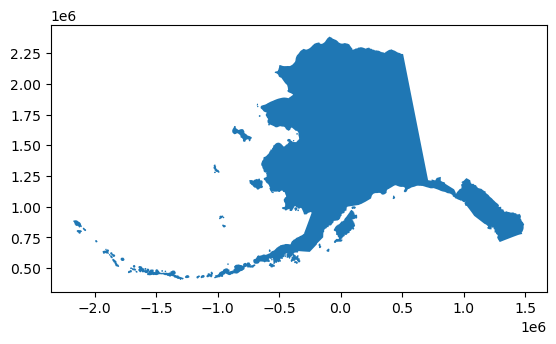

In [48]:
alaska.plot()

In [49]:
print(f"CRS: {places.crs}")

places.head(3)

CRS: epsg:3338


,scalerank,natscale,labelrank,featurecla,name,namepar,namealt,nameascii,adm0cap,capalt,capin,worldcity,megacity,sov0name,sov_a3,adm0name,adm0_a3,adm1name,iso_a2,note,latitude,longitude,pop_max,pop_min,pop_other,rank_max,rank_min,meganame,ls_name,min_zoom,ne_id,geometry
0,10,1,5,Admin-1 region capital,Bombo,None,None,Bombo,0,0,None,0,0,Uganda,UGA,Uganda,UGA,Bamunanika,UG,None,0.583299,32.533300,75000,21000,0.0,8,7,None,None,7.0,1159113923,POINT (-4899666.005 13174532.095)
1,10,1,5,Admin-1 region capital,Fort Portal,None,None,Fort Portal,0,0,None,0,0,Uganda,UGA,Uganda,UGA,Kabarole,UG,None,0.671004,30.275002,42670,42670,0.0,7,7,None,None,7.0,1159113959,POINT (-4608734.425 13329768.542)
2,10,1,3,Admin-1 region capital,Potenza,None,None,Potenza,0,0,None,0,0,Italy,ITA,Italy,ITA,Basilicata,IT,None,40.642002,15.798997,69060,69060,0.0,8,8,None,None,7.0,1159117259,POINT (3214027.057 9658638.990)


<Axes: >

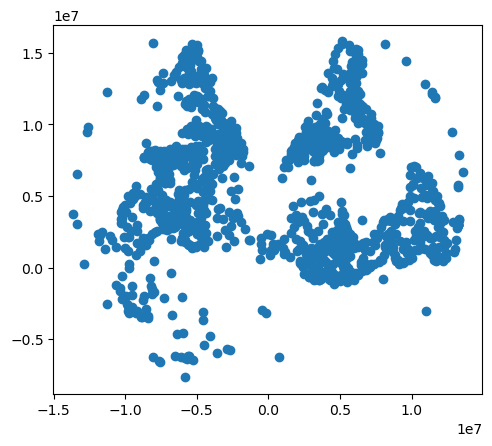

In [50]:
places.plot()

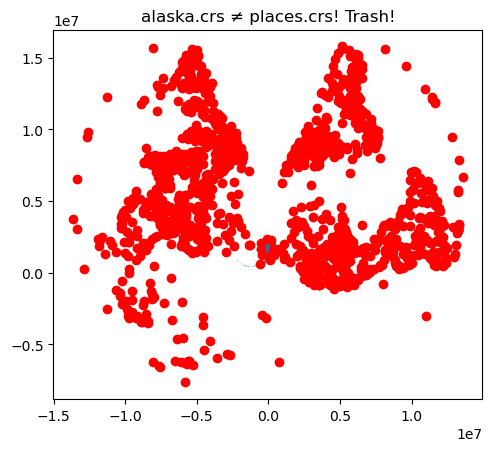

In [51]:
# Trouble
fig, ax = plt.subplots()

alaska.plot(ax=ax)
places.plot(ax=ax, color='red')
plt.title("alaska.crs ≠ places.crs! Trash!")

plt.show()

In [52]:
alaska.crs == places.crs

True

In [53]:
places = places.to_crs(alaska.crs)
assert alaska.crs == places.crs

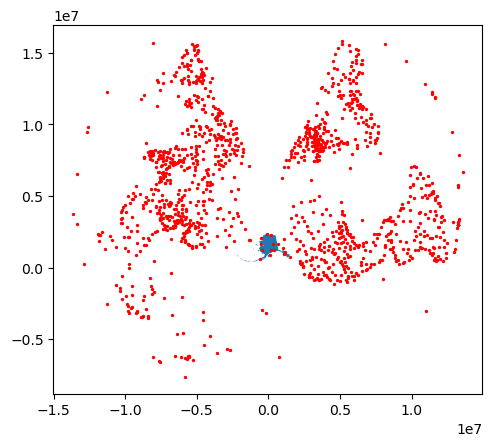

In [54]:
fig, ax = plt.subplots()

alaska.plot(ax=ax)
places.plot(ax=ax, color='red', markersize=2)

plt.show()

**Clipping** means using a polygon (or polygons) to keep only the parts of the geometries that fall inside them. Clipping a geopandas.GeoDataFrame is simple using the geopandas clip() function. The general syntax is:

```python
updated_geodf = geopandas.clip(geodf, mask)
```

where:

- `updated_geodf` is the output of the function: the intersection of the geometries in `geodf` with `mask`,
- `geodf` is the `geopandas.GeoDataFrame` we want to clip,
- `mask` is a `geopandas.GeoDataFrame` with the polygon(s) we want to use for clipping (we will see later that it can also be a bounding box). This `mask` must be in the same CRS as `geodf`!

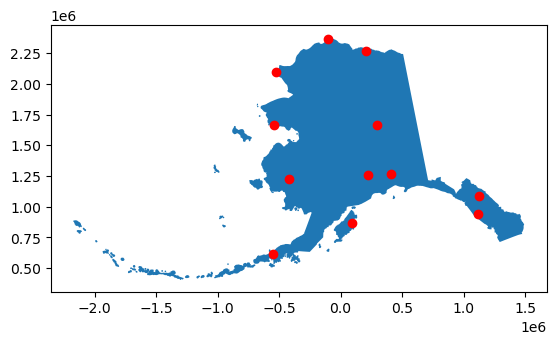

In [55]:
# Clip populated places to Alaska multipolygon
ak_places = gpd.clip(places, alaska)

fig, ax = plt.subplots()
alaska.plot(ax=ax)
ak_places.plot(ax=ax, color='red')
plt.show()

## Prepare roads

In [56]:
print(roads.crs)

roads.head(3)

EPSG:4326


,scalerank,featurecla,type,sov_a3,note,edited,name,namealt,namealtt,routeraw,question,length_km,toll,ne_part,label,label2,local,localtype,localalt,labelrank,ignore,add,rwdb_rd_id,orig_fid,prefix,uident,continent,expressway,level,min_zoom,min_label,geometry
0,8,Road,Secondary Highway,CAN,None,"Version 1.5: Changed alignment, a few adds in ...",None,None,None,None,0,3,0,ne_1d4_original,None,None,None,None,None,0,0,0,0,0,None,314705,North America,0,None,7.1,9.6,"LINESTRING (-133.32533 62.21571, -133.31664 62..."
1,7,Road,Secondary Highway,USA,None,"Version 1.5: Changed alignment, a few adds in ...",83,None,None,None,0,164,0,ne_1d4_original,None,None,None,None,None,0,0,0,0,0,None,108105,North America,0,Federal,7.0,8.6,"LINESTRING (-100.50543 42.80753, -100.53495 42..."
2,7,Road,Secondary Highway,USA,None,"Version 1.5: Changed alignment, a few adds in ...",840,None,None,None,0,98,0,ne_1d4_original,None,None,None,None,None,0,0,0,0,0,None,0,North America,0,U/C,7.0,9.5,"LINESTRING (-87.27432 36.02439, -87.22916 35.9..."


<Axes: >

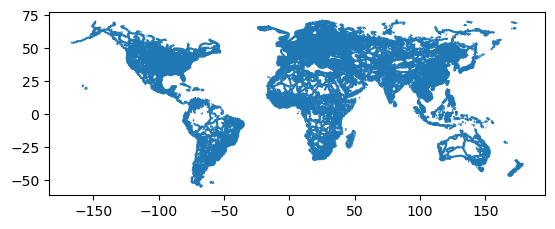

In [57]:
roads.plot()

<Axes: >

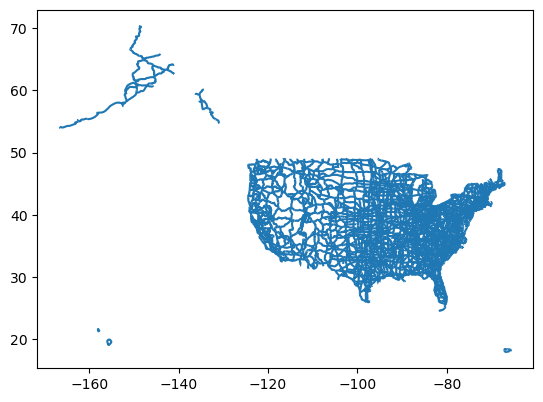

In [58]:
usa_roads = roads[roads['sov_a3'] == 'USA']
usa_roads.plot()

#### **Caution**: Reduce your tabular data before reducing via geometries
**Geospatial operations are usually costly in terms of computing power. The more detailed our geometries are, the longer it takes to do geospatial computations. It’s a good practice to reduce your data as much as possible before applying any geospatial transformation.**

We will now compose functions to clip `usa_roads` using the `alaska` multipolygon. Notice we are using the output of `usa_roads.to_crs(alaska.crs)` directly and thus not changing the `usa_roads` geo-dataframe or creating new variables:



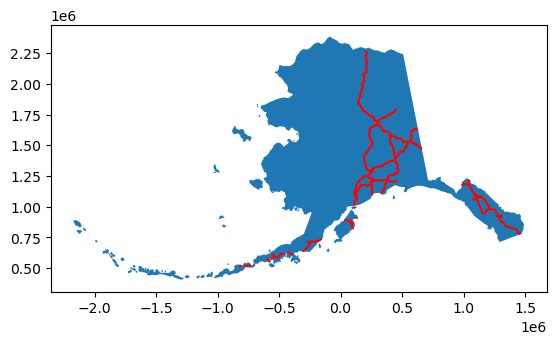

In [60]:
# Clip usa_roads to alaska geometry
ak_roads = gpd.clip(usa_roads.to_crs(alaska.crs), alaska)


fig, ax = plt.subplots()
alaska.plot(ax=ax)
ak_roads.plot(ax=ax, color='red')
plt.show()

Clipping to the alaska polygons *keeps only the pieces that cross land*, so clipping exactly to the polygons isn’t what we want here...

### Clip with a bounding box

We will clip the `usa_roads` geo-dataframe with the **bounding box** of alaska instead of its polygons. A bounding box is the smallest rectangle that contains all the geometries. It is defined by four coordinates, `minx`, `miny`, `maxx`, `maxy`:

![alt text](https://meds-eds-220.github.io/MEDS-eds-220-course/book/images/lesson-13/bounding-box.png)

In [61]:
# total_bounds attribute of a geo-dataframe gives us these four values:

alaska.total_bounds

array([-2175729.73162241,   404545.10791528,  1493082.30904445,
        2383808.43520815])

In [ ]:
# gpd.clip() accepts these four values directly as the mask,
# so we can clip the roads to Alaska’s bounding box in one step:

ak_complete_roads = gpd.clip(usa_roads.to_crs(alaska.crs), alaska.total_bounds)
                            # reprojecting usa_roads to alaska.crs before clipping

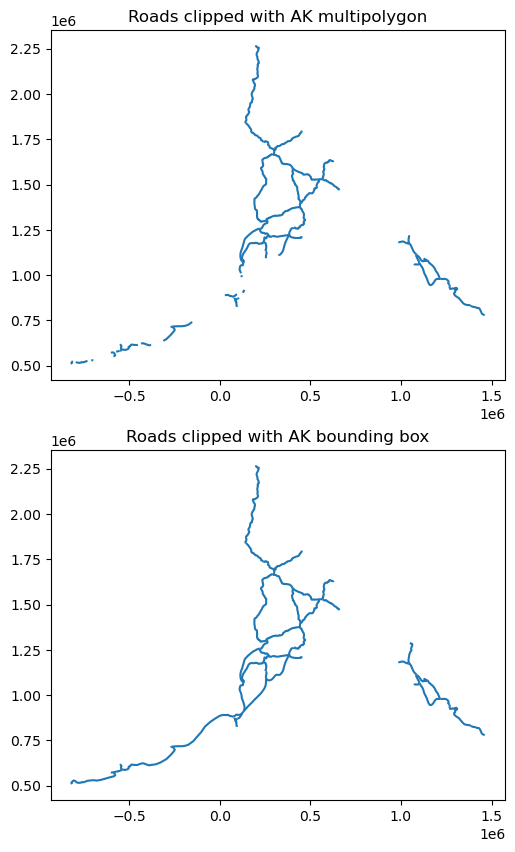

In [63]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10,10))

ak_roads.plot(ax=ax1)
ax1.set_title('Roads clipped with AK multipolygon')

ak_complete_roads.plot(ax=ax2)
ax2.set_title('Roads clipped with AK bounding box')

plt.show()

## Measuring lengths

To understand the difference between the two clips, we will compare the lengths of their roads. Geo-dataframes have a length attribute that calculates the `length` of each line from its geometry, **in the units of the CRS**. Let’s try it on one road in Alaska, the road with index 1138:

In [72]:
print("See UserWarning!")
usa_roads.loc[[1138]].length

See UserWarning!


/var/folders/wg/0_88qqzd1ndd9cc98n11g6t00000gn/T/ipykernel_34431/2223297428.py:2: UserWarning: Geometry is in a geographic CRS. Results from 'length' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  usa_roads.loc[[1138]].length


1138    4.051932
dtype: float64

geopandas gives us a warning, and the result is not a length we can use. **`usa_roads` is in EPSG:4326, a *geographic* CRS whose units are degrees**. A degree is not a fixed distance: one degree of longitude is about 111 km at the equator but only about 55 km in southern Alaska.

**To measure lengths, we first need to reproject to a projected CRS whose units are meters. Let’s use the EPSG:3338 CRS for Alaska:**

In [71]:
# Reproject to the Alaska CRS and convert meters to kilometers
usa_roads.loc[[1138]].to_crs('epsg:3338').length / 1000

1138    287.473411
dtype: float64

## How does clippin' affect the data?

In [74]:
print('Number of roads (polygon clip):', len(ak_roads))
print('Number of roads (bbox clip):   ', len(ak_complete_roads))

# Divide by 1000 to convert meters to kilometers
print('Total length in km (polygon clip):', round(ak_roads.length.sum() / 1000))
print('Total length in km (bbox clip):   ', round(ak_complete_roads.length.sum() / 1000))

Number of roads (polygon clip): 56
Number of roads (bbox clip):    56
Total length in km (polygon clip): 6069
Total length in km (bbox clip):    7111


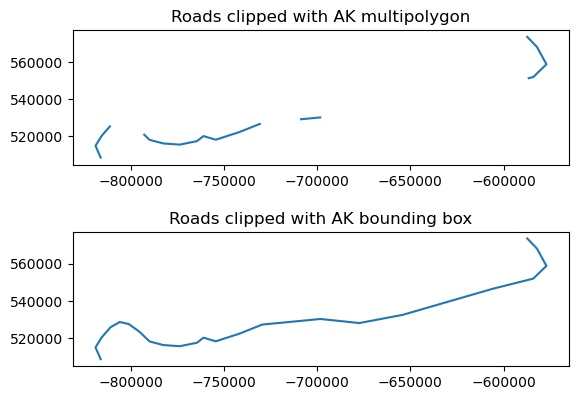

In [75]:
fig, (ax1, ax2) = plt.subplots(2, 1)

ak_roads.loc[[1138]].plot(ax=ax1)
ax1.set_title('Roads clipped with AK multipolygon')

ak_complete_roads.loc[[1138]].plot(ax=ax2)
ax2.set_title('Roads clipped with AK bounding box')

plt.show()

In [ ]:
print('Total length of 1138 in km (polygon clip):', round(ak_roads.loc[[1138]].length/1000))
print('Total length of 1138 in km (bbox clip):   ', round(ak_complete_roads.loc[[1138]].length/1000))

Total length of 1138 in km (polygon clip): 1138    132.0
dtype: float64
Total length of 1138 in km (bbox clip):    1138    287.0
dtype: float64


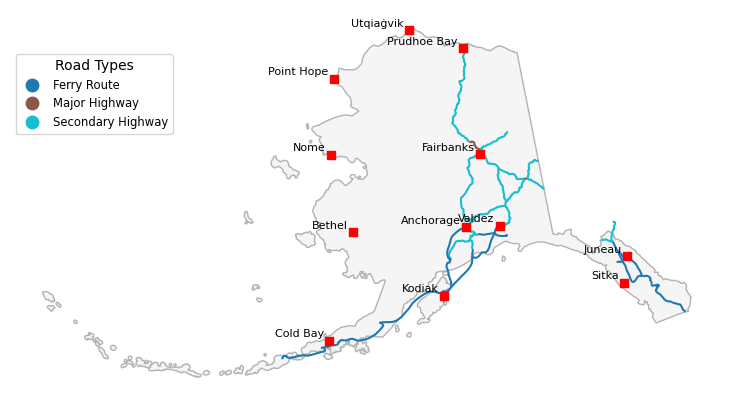

In [91]:
fig, ax = plt.subplots(figsize = (11,5))
ax.axis('off')

alaska.plot(ax=ax, color = 'whitesmoke', edgecolor = '0.7')

ak_complete_roads.plot(ax=ax, 
                  column = 'type',
                  legend=True,
                  legend_kwds = {'title' : 'Road Types',
                                 'loc' : 'upper left',
                                 'bbox_to_anchor' : (0, 0.9),
                                 'fontsize' : 'small'}
                    )

ak_places.plot(ax=ax,
               zorder = 2, 
               color = 'red',
               marker = 's' # Square marker
               )

# Add city names as text annotations
for x,y,name in zip(ak_places.geometry.x, ak_places.geometry.y, ak_places['name']):
    ax.text(x-30000, y+20000, name, fontsize = 8, ha = 'right')

plt.show()

